
# 2. CRM Analytics

## 2.1 RFM Analysis

RFM analysis helps us understand customer purchasing behavior.

We will use the following rules:

- Snapshot day: 712
- Observation window: Days 347 to 711
- Recency: Days since the last positive-value purchase
- Frequency: Number of positive-value baskets in the last 365 days
- Monetary: Total spending in the last 365 days

Customers without purchases during the observation window will remain in the dataset.

Our goal is to identify different customer groups based on their recent shopping behavior.


In [1]:
from pathlib import Path
import sys
from sqlalchemy import text
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lifetimes import BetaGeoFitter, GammaGammaFitter
from scipy.special import hyp2f1

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.database import get_engine

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

engine = get_engine()

In [2]:
# Analysis parameters
SNAPSHOT_DAY = 712
LOOKBACK_DAYS = 365

WINDOW_START = SNAPSHOT_DAY - LOOKBACK_DAYS

In [3]:
# Load all positive-value shopping baskets
query = text("""
    SELECT
        household_key,
        BASKET_ID,
        MIN(`DAY`) AS basket_day,
        SUM(SALES_VALUE) AS basket_sales
    FROM raw_transaction_data
    GROUP BY household_key, BASKET_ID
    HAVING SUM(SALES_VALUE) > 0
""")

with engine.connect() as connection:
    positive_baskets = pd.read_sql_query(
        query,
        con=connection
    )

positive_baskets["basket_sales"] = pd.to_numeric(positive_baskets["basket_sales"])

# Keep every customer with a positive purchase history
customers = positive_baskets[
    ["household_key"]
].drop_duplicates()

# Find the last purchase across all observed days
last_purchases = (
    positive_baskets
    .groupby("household_key", as_index=False)
    .agg(last_purchase_day = ("basket_day", "max"))
)

# Select the last 365 days
window_baskets = positive_baskets.loc[
    positive_baskets["basket_day"].between(
        WINDOW_START,
        SNAPSHOT_DAY -1
    )
].copy()

# Calculate frequency and monetary value

window_metrics = (
    window_baskets
    .groupby("household_key", as_index=False)
    .agg(
        frequency=("BASKET_ID", "nunique"),
        monetary=("basket_sales", "sum")
    )
)

# Merge customer-level metrics
rfm_df =(
    customers
    .merge(
        last_purchases,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        window_metrics,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
)

# Calculate recency
rfm_df["recency"] = (
    SNAPSHOT_DAY - rfm_df["last_purchase_day"]
)

# Customers without recent purchases
rfm_df["frequency"] = (
    rfm_df["frequency"].fillna(0).astype(int)
)

rfm_df["monetary"] = (
    rfm_df["monetary"].fillna(0)
)

rfm_df = rfm_df[
    ["household_key", "recency", "frequency", "monetary"]
]

print("RFM Dataset Shape:", rfm_df.shape)

display(rfm_df.head())

RFM Dataset Shape: (2500, 4)


,household_key,recency,frequency,monetary
0,2375,7,92,"2,095.52"
1,1364,2,78,"1,286.80"
2,1130,1,174,"3,160.53"
3,1173,75,20,379.24
4,98,2,151,"2,046.25"


In [4]:
print("Total Customers:", len(rfm_df))

print(
    "Customers with No Purchases in Last 365 Days:",
    (rfm_df["frequency"] == 0).sum()
)

print("\nMissing Values:")
display(rfm_df.isna().sum())

display(
    rfm_df[
        ["recency", "frequency", "monetary"]
    ].describe().T.round(2)
)

Total Customers: 2500
Customers with No Purchases in Last 365 Days: 21

Missing Values:


household_key    0
recency          0
frequency        0
monetary         0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
recency,"2,500.00",26.58,62.79,1.00,2.00,7.00,21.00,658.00
frequency,"2,500.00",61.96,67.92,0.00,19.00,43.00,82.00,721.00
monetary,"2,500.00","1,858.74","2,033.93",0.00,468.47,"1,196.95","2,544.88","26,771.59"



## 2.2 RFM Scoring

We will assign scores from 1 to 5 for each RFM metric.

The scoring rules are:

- Recency: Lower values receive higher scores.
- Frequency: Higher values receive higher scores.
- Monetary: Higher values receive higher scores.

We will use percentile ranks to handle repeated values.

Customers with the same metric value will receive the same score.


In [5]:
def calculate_rfm_score(
    series: pd.Series,
    higher_is_better: bool = True,
    n_groups: int = 5,
) -> pd.Series:
    """Calculate RFM scores using percentile ranks."""

    # To sort
    percentile_ranks = series.rank(
        # It uses the average of the rank numbers for equal values.
        method="average",
        # Converts the ranking into percentile rank values ​​between 0 and 1.
        pct=True,
        # Small values ​​receive a low percentile rank, while large values ​​receive a high percentile rank.
        ascending=higher_is_better
    )

    scores = (
        # Rounding up
        np.ceil(percentile_ranks * n_groups)
        # Setting lower and upper limits
        .clip(lower=1, upper=n_groups)
        .astype(int)
    )

    return scores

In [6]:
# Calculate individual RFM scores
rfm_df["R_score"] = calculate_rfm_score(
    rfm_df["recency"],
    higher_is_better=False,
)

rfm_df["F_score"] = calculate_rfm_score(
    rfm_df["frequency"],
    higher_is_better=True,
)

rfm_df["M_score"] = calculate_rfm_score(
    rfm_df["monetary"],
    higher_is_better=True,
)

# Combine scores into a three-digit RFM code
rfm_df["RFM_score"] = (
    rfm_df[["R_score", "F_score", "M_score"]]
    .astype(str)
    .agg("".join, axis=1)
)

display(rfm_df.head(10))

,household_key,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,2375,7,92,"2,095.52",3,4,4,344
1,1364,2,78,"1,286.80",5,4,3,543
2,1130,1,174,"3,160.53",5,5,5,555
3,1173,75,20,379.24,1,2,2,122
4,98,2,151,"2,046.25",5,5,4,554
5,1172,2,110,"3,146.32",5,5,5,555
6,1060,40,29,"2,690.61",1,2,4,124
7,1351,15,38,257.67,2,3,1,231
8,212,15,55,"1,530.16",2,4,3,243
9,2052,121,4,82.95,1,1,1,111


In [7]:
for score_column in ["R_score", "F_score", "M_score"]:

    print(f"\n{score_column} Distribution")

    print(
        rfm_df[score_column]
        .value_counts()
        .sort_index()
    )

print("\nRFM Score Summary")

display(
    rfm_df[
        ["R_score", "F_score", "M_score"]
    ].describe().T
)



R_score Distribution
R_score
1    509
2    466
3    545
4    351
5    629
Name: count, dtype: int64

F_score Distribution
F_score
1    501
2    490
3    512
4    500
5    497
Name: count, dtype: int64

M_score Distribution
M_score
1    500
2    500
3    500
4    500
5    500
Name: count, dtype: int64

RFM Score Summary


,count,mean,std,min,25%,50%,75%,max
R_score,"2,500.00",3.05,1.46,1.00,2.00,3.00,5.00,5.00
F_score,"2,500.00",3.00,1.41,1.00,2.00,3.00,4.00,5.00
M_score,"2,500.00",3.00,1.41,1.00,2.00,3.00,4.00,5.00



## 2.3 RFM Customer Segmentation

We will divide customers into segments based on their RFM scores.

The main customer segments are:
- Champions
- Loyal Customers
- Potential Loyalists
- Recent Low Frequency
- Needs Attention
- At Risk
- Hibernating
- Dormant (365d)

Customers with no positive-value purchases in the last 365 days will be classified as Dormant.

Our goal is to understand customer groups and support business decisions.


In [8]:
# Define customer segment conditions
conditions = [
    # Customers without purchases in the last 365 days
    rfm_df["frequency"].eq(0),

    # High-value and recently active customers
    (
        rfm_df["R_score"].ge(4)
        & rfm_df["F_score"].ge(4)
        & rfm_df["M_score"].ge(4)
    ),

    # Loyal customers
    (
        rfm_df["R_score"].ge(4)
        & rfm_df["F_score"].ge(4)
    ),

    # Potential loyalists
    (
        rfm_df["R_score"].ge(4)
        & rfm_df["F_score"].between(2, 3)
    ),

    # Recently active but low frequency
    (
        rfm_df["R_score"].ge(4)
        & rfm_df["F_score"].eq(1)
    ),

    # Medium recency customers
    rfm_df["R_score"].eq(3),

    # Previously active but less recent
    (
        rfm_df["R_score"].le(2)
        & rfm_df["F_score"].ge(3)
    ),

    # Low frequency and low recency
    (
        rfm_df["R_score"].le(2)
        & rfm_df["F_score"].le(2)
    ),
]

segment_names = [
    "Dormant (365d)",
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Low Frequency",
    "Needs Attention",
    "At Risk",
    "Hibernating",
]

# Assign customer segments
rfm_df["segment"] = np.select(
    conditions,
    segment_names,
    default="Unassigned"
)

# Validate segmentation
assert (rfm_df["segment"] != "Unassigned").all()

print("Customer Segment Distribution")

display(
    rfm_df["segment"].value_counts()
)

Customer Segment Distribution


segment
Hibernating             643
Needs Attention         545
Champions               533
At Risk                 311
Potential Loyalists     286
Loyal Customers         117
Recent Low Frequency     44
Dormant (365d)           21
Name: count, dtype: int64

Let’s examine the business performance of the segments.

In [9]:
segment_summary = (
    rfm_df
    .groupby("segment", as_index=False)
    .agg(
        customer_count=("household_key", "size"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
)

segment_summary["customer_share_pct"] = (
    segment_summary["customer_count"]
    / len(rfm_df) * 100
)

segment_summary["monetary_share_pct"] = (
    segment_summary["total_monetary"]
    / segment_summary["total_monetary"].sum() * 100
)

segment_summary = (
    segment_summary
    .sort_values("total_monetary", ascending=False)
    .round(2)
)

display(segment_summary)

,segment,customer_count,median_recency,avg_frequency,avg_monetary,total_monetary,customer_share_pct,monetary_share_pct
1,Champions,533,2.00,141.98,"4,230.06","2,254,621.19",21.32,48.52
5,Needs Attention,545,7.00,57.21,"1,923.07","1,048,073.40",21.80,22.55
0,At Risk,311,20.00,59.22,"1,763.86","548,560.40",12.44,11.80
6,Potential Loyalists,286,2.00,34.91,"1,238.77","354,286.89",11.44,7.62
3,Hibernating,643,36.00,14.10,453.10,"291,344.20",25.72,6.27
4,Loyal Customers,117,2.00,86.79,"1,167.37","136,582.24",4.68,2.94
7,Recent Low Frequency,44,2.00,9.82,304.19,"13,384.30",1.76,0.29
2,Dormant (365d),21,487.00,0.00,0.00,0.00,0.84,0.00


At Risk: To understand the decline in activity among customers who have previously made significant expenditures, we must examine this segment in detail.

In [10]:
rfm_df.head()

,household_key,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
0,2375,7,92,"2,095.52",3,4,4,344,Needs Attention
1,1364,2,78,"1,286.80",5,4,3,543,Loyal Customers
2,1130,1,174,"3,160.53",5,5,5,555,Champions
3,1173,75,20,379.24,1,2,2,122,Hibernating
4,98,2,151,"2,046.25",5,5,4,554,Champions



### 2.3.1 RFM Segment Performance

We will compare customer share and monetary share across RFM segments.

This analysis helps us understand which customer groups contribute the most to total spending.

We will also check whether segment names correctly describe customer behavior before making business recommendations.


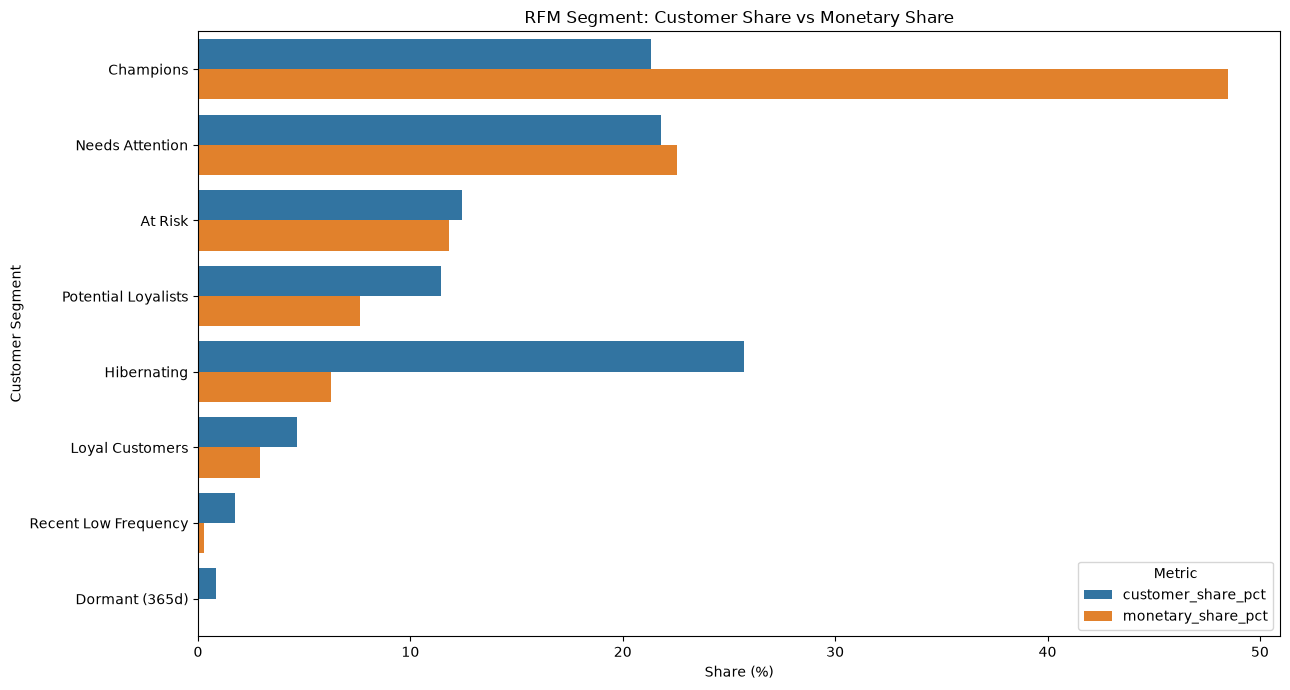

In [11]:
# Convert segment metrics to long format
segment_plot_df = segment_summary.melt(
    id_vars="segment",
    value_vars=[
        "customer_share_pct",
        "monetary_share_pct",
    ],
    var_name="metric",
    value_name="share_pct",
)

# Create segment comparison chart
plt.figure(figsize=(13, 7))

sns.barplot(
    data=segment_plot_df,
    x="share_pct",
    y="segment",
    hue="metric",
    order=segment_summary["segment"],
    errorbar=None,
)

plt.title("RFM Segment: Customer Share vs Monetary Share")
plt.xlabel("Share (%)")
plt.ylabel("Customer Segment")
plt.legend(title="Metric")

plt.tight_layout()
plt.show()


### 2.3.2 Absolute Recency Validation

RFM scores compare customers based on relative rankings.

However, a low Recency score does not always mean that a customer is inactive.

In this section, we will:
- Examine actual Recency values for each segment.
- Calculate Recency percentiles.
- Identify customers with long periods of inactivity.
- Evaluate whether the segment names match customer behavior.

We will not change the original RFM metrics.


In [12]:
rfm_df.head()

,household_key,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
0,2375,7,92,"2,095.52",3,4,4,344,Needs Attention
1,1364,2,78,"1,286.80",5,4,3,543,Loyal Customers
2,1130,1,174,"3,160.53",5,5,5,555,Champions
3,1173,75,20,379.24,1,2,2,122,Hibernating
4,98,2,151,"2,046.25",5,5,4,554,Champions


In [13]:
# Calculate absolute recency statistics by segment
recency_validation = (
    rfm_df
    .groupby("segment")
    .agg(
        customer_count=("household_key", "size"),
        min_recency=("recency", "min"),
        median_recency=("recency", "median"),
        p75_recency=("recency", lambda x: x.quantile(0.75)),
        p90_recency=("recency", lambda x: x.quantile(0.90)),
        max_recency=("recency", "max"),
        customers_over_30d=("recency", lambda x: x.gt(30).sum()),
        customers_over_60d=("recency", lambda x: x.gt(60).sum()),
        customers_over_90d=("recency", lambda x: x.gt(90).sum()),
    )
    .reset_index()
)

# Calculate inactivity percentages
for days in [30, 60, 90]:
    recency_validation[f"over_ {days}d_pct"] = (
        recency_validation[f"customers_over_{days}d"]
        / recency_validation["customer_count"]
        * 100
    )

recency_validation = (
    recency_validation
    .sort_values("median_recency")
    .round(2)
)

display(recency_validation)

,segment,customer_count,min_recency,median_recency,p75_recency,p90_recency,max_recency,customers_over_30d,customers_over_60d,customers_over_90d,over_ 30d_pct,over_ 60d_pct,over_ 90d_pct
1,Champions,533,1,2.00,3.00,4.00,4,0,0,0,0.00,0.00,0.00
7,Recent Low Frequency,44,1,2.00,3.00,4.00,4,0,0,0,0.00,0.00,0.00
6,Potential Loyalists,286,1,2.00,3.00,4.00,4,0,0,0,0.00,0.00,0.00
4,Loyal Customers,117,1,2.00,3.00,4.00,4,0,0,0,0.00,0.00,0.00
5,Needs Attention,545,5,7.00,8.00,10.00,10,0,0,0,0.00,0.00,0.00
0,At Risk,311,11,20.00,31.00,61.00,259,81,34,16,26.05,10.93,5.14
3,Hibernating,643,11,36.00,78.50,143.60,341,359,207,137,55.83,32.19,21.31
2,Dormant (365d),21,371,487.00,626.00,643.00,658,21,21,21,100.00,100.00,100.00



### 2.3.3 RFM Segment Refinement

The absolute Recency analysis showed that some segment names did not fully describe customer behavior.

For example, customers in the "Needs Attention" segment made purchases within the last 10 days.

We will update some segment names to make them easier to interpret.

The original RFM scores and segmentation rules will remain unchanged.

These segments describe relative purchasing behavior, not predicted churn risk.


In [14]:

# Define more descriptive segment names
segment_mapping = {
    "Needs Attention": "Recently Active",
    "At Risk": "Less Recent - Frequent",
    "Hibernating": "Less Recent - Infrequent",
}

# Update segment labels
rfm_df["segment"] = (
    rfm_df["segment"]
    .replace(segment_mapping)
)

# Recalculate segment statistics
segment_summary = (
    rfm_df
    .groupby("segment", as_index=False)
    .agg(
        customer_count=("household_key", "size"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
)

# Calculate segment shares
segment_summary["customer_share_pct"] = (
    segment_summary["customer_count"]
    / len(rfm_df) * 100
)

segment_summary["monetary_share_pct"] = (
    segment_summary["total_monetary"]
    / segment_summary["total_monetary"].sum() * 100
)

# Sort by monetary contribution
segment_summary = (
    segment_summary
    .sort_values("total_monetary", ascending=False)
    .round(2)
)

assert segment_summary["customer_count"].sum() == 2500
assert rfm_df["segment"].nunique() == 8

display(segment_summary)


,segment,customer_count,median_recency,avg_frequency,avg_monetary,total_monetary,customer_share_pct,monetary_share_pct
0,Champions,533,2.00,141.98,"4,230.06","2,254,621.19",21.32,48.52
7,Recently Active,545,7.00,57.21,"1,923.07","1,048,073.40",21.80,22.55
2,Less Recent - Frequent,311,20.00,59.22,"1,763.86","548,560.40",12.44,11.80
5,Potential Loyalists,286,2.00,34.91,"1,238.77","354,286.89",11.44,7.62
3,Less Recent - Infrequent,643,36.00,14.10,453.10,"291,344.20",25.72,6.27
4,Loyal Customers,117,2.00,86.79,"1,167.37","136,582.24",4.68,2.94
6,Recent Low Frequency,44,2.00,9.82,304.19,"13,384.30",1.76,0.29
1,Dormant (365d),21,487.00,0.00,0.00,0.00,0.84,0.00


Notes:
* BG-NBD Model: Estimates the number of repeat purchases expected from a customer in the future.
* Gamma-Gamma Model: It estimates the customer's expected average purchase amount, provided that the appropriate model assumptions are met.
* CLTV Estimation: It estimates future customer spending by combining the expected frequency and value of purchases. For CLTV based on actual profit, we also require information regarding profit margins.


## 2.4 CLTV Data Preparation

We will prepare customer-level data for BG-NBD and Gamma-Gamma models.

BG-NBD uses frequency, recency, and customer age (T) to estimate future purchasing activity.

Gamma-Gamma uses repeat purchase frequency and average monetary value.

We will group baskets by customer and day because a customer may have multiple baskets on the same day.

We will use the same 365-day observation window as the RFM analysis.


In [15]:
window_baskets.head()

,household_key,BASKET_ID,basket_day,basket_sales
120259,1321,32090402409,347,6.14
120364,1507,32090554285,347,20.82
120471,1340,32090713604,347,5.08
120498,1751,32090738871,347,10.98
120585,202,32090878893,347,2.75


In [16]:
# 1. Aggregate baskets by customer and day
purchase_days = (
    window_baskets
    .groupby(
        ["household_key", "basket_day"],
        as_index=False
    )
    .agg(
        daily_sales=("basket_sales", "sum"),
        basket_count=("BASKET_ID", "nunique"),
    )
    .sort_values(["household_key", "basket_day"])
)

# 2. Number each customer's purchase days
purchase_days["purchase_sequence"] = (
    purchase_days
    .groupby("household_key")
    # Each customer is assigned a queue number that starts from zero for each shopping day.
    .cumcount()
    # We mark the first day of shopping as 1, and the second as 2.
    .add(1)
)

# 3. Calculate customer-level purchase metrics
cltv_df = (
    purchase_days
    .groupby("household_key", as_index=False)
    .agg(
        first_purchase_day=("basket_day", "min"),
        last_purchase_day=("basket_day", "max"),
        purchase_day_count=("basket_day", "nunique"),
    )
)

# Number of distinct days on which additional purchases were made, excluding the initial day of purchase
cltv_df["frequency"] = (
    cltv_df["purchase_day_count"] - 1
)

# Last shopping day − first shopping day
cltv_df["recency"] = (
    cltv_df["last_purchase_day"]
    - cltv_df["first_purchase_day"]
)

# Analysis day − first shopping day
cltv_df["T"] = (
    SNAPSHOT_DAY - cltv_df["first_purchase_day"]
)

# Average spending on subsequent shopping days, excluding the initial shopping day
# 4. Exclude each customer's first purchase day
repeat_days = purchase_days.loc[
    purchase_days["purchase_sequence"] > 1
]

repeat_monetary = (
    repeat_days
    .groupby("household_key", as_index=False)
    .agg(
        monetary_value=("daily_sales", "mean")
    )
)

# 5. Merge monetary information
cltv_df = cltv_df.merge(
    repeat_monetary,
    on="household_key",
    how="left",
    validate="one_to_one"
)

cltv_df["monetary_value"] = (
    cltv_df["monetary_value"].fillna(0)
)

# 6. Select model variables
cltv_df = cltv_df[
    [
        "household_key",
        "frequency",
        "recency",
        "T",
        "monetary_value",
    ]
]

display(cltv_df.head())

,household_key,frequency,recency,T,monetary_value
0,1,46,354,360,52.52
1,2,16,253,297,57.50
2,3,18,343,352,35.51
3,4,11,273,358,21.72
4,5,14,285,294,17.18


In [17]:
print("Total CLTV Customers:", len(cltv_df))

print(
    "Customers Without Repeat Purchases:",
    (cltv_df["frequency"] == 0).sum()
)

print("\nMissing Values:")
display(cltv_df.isna().sum())

assert (cltv_df["frequency"] >= 0).all()
assert (cltv_df["recency"] >= 0).all()
assert (cltv_df["recency"] <= cltv_df["T"]).all()
assert cltv_df["household_key"].is_unique

display(
    cltv_df[
        ["frequency", "recency", "T", "monetary_value"]
    ].describe().T.round(2)
)

# Check the Gamma-Gamma independence assumption
repeat_customers = cltv_df.loc[
    cltv_df["frequency"] > 0
]

print("\nFrequency vs Monetary Correlation")

print(
    repeat_customers[
        ["frequency", "monetary_value"]
    ].corr(method="pearson")
)

Total CLTV Customers: 2479
Customers Without Repeat Purchases: 31

Missing Values:


household_key     0
frequency         0
recency           0
T                 0
monetary_value    0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
frequency,"2,479.00",50.33,45.42,0.00,17.00,38.00,71.00,303.00
recency,"2,479.00",318.37,72.67,0.00,315.00,349.00,359.00,364.00
T,"2,479.00",340.83,50.93,5.00,345.00,359.00,364.00,365.00
monetary_value,"2,479.00",36.03,23.05,0.00,20.06,31.49,46.69,224.25



Frequency vs Monetary Correlation
                frequency  monetary_value
frequency            1.00           -0.00
monetary_value      -0.00            1.00



## 2.5 Calibration and Holdout Data

We will split our 365-day observation window into two periods:

- Calibration period: Days 347–621
- Holdout period: Days 622–711

The calibration period will be used to train the BG-NBD model.

The holdout period will be used to evaluate future purchase predictions.

We will include customers who made at least one purchase during the calibration period.

New customers who appear only in the holdout period will be analyzed separately.


In [18]:
# Define time periods
HOLDOUT_DAYS = 90

CALIBRATION_END = SNAPSHOT_DAY - HOLDOUT_DAYS - 1
HOLDOUT_START = CALIBRATION_END + 1

# Split customer purchase days
calibration_days = purchase_days.loc[
    purchase_days["basket_day"].between(
        WINDOW_START,
        CALIBRATION_END
    )
].copy()

holdout_days = purchase_days.loc[
    purchase_days["basket_day"].between(
        HOLDOUT_START,
        SNAPSHOT_DAY - 1
    )
].copy()

# Create calibration metrics
calibration_df = (
    calibration_days
    .groupby("household_key", as_index=False)
    .agg(
        first_day=("basket_day", "min"),
        last_day=("basket_day", "max"),
        purchase_day_count=("basket_day", "nunique"),
    )
)

calibration_df["frequency_cal"] = (
    calibration_df["purchase_day_count"] - 1
)

calibration_df["recency_cal"] = (
    calibration_df["last_day"]
    - calibration_df["first_day"]
)

calibration_df["T_cal"] = (
    HOLDOUT_START - calibration_df["first_day"]
)


# Count purchases during the holdout period
holdout_df = (
    holdout_days
    .groupby("household_key", as_index=False)
    .agg(
        frequency_holdout=("basket_day", "nunique")
    )
)

# Merge calibration and holdout data
cal_holdout_df = calibration_df.merge(
    holdout_df,
    on="household_key",
    how="left",
    validate="one_to_one"
)

cal_holdout_df["frequency_holdout"] = (
    cal_holdout_df["frequency_holdout"]
    .fillna(0)
    .astype(int)
)

# Select modeling variables
cal_holdout_df = cal_holdout_df[
    [
        "household_key",
        "frequency_cal",
        "recency_cal",
        "T_cal",
        "frequency_holdout",
    ]
]

print("Calibration Customers:", len(cal_holdout_df))

display(cal_holdout_df.head())

Calibration Customers: 2453


,household_key,frequency_cal,recency_cal,T_cal,frequency_holdout
0,1,34,268,270,12
1,2,14,205,207,2
2,3,15,216,262,3
3,4,10,263,268,1
4,5,12,171,204,2


In [19]:
print("Calibration Period:", WINDOW_START, "-", CALIBRATION_END)
print("Holdout Period:", HOLDOUT_START, "-", SNAPSHOT_DAY - 1)

print("\nCalibration Customers:", len(cal_holdout_df))

print(
    "Customers Without Holdout Purchases:",
    cal_holdout_df["frequency_holdout"].eq(0).sum()
)

# Identify customers who first appear in holdout
holdout_only = (
    set(holdout_days["household_key"])
    - set(calibration_days["household_key"])
)

print("Holdout-Only Customers:", len(holdout_only))

# Check modeling data
assert cal_holdout_df["household_key"].is_unique
assert (cal_holdout_df["frequency_cal"] >= 0).all()
assert (cal_holdout_df["recency_cal"] >= 0).all()
assert (
    cal_holdout_df["recency_cal"]
    <= cal_holdout_df["T_cal"]
).all()

print("\nModeling Data Summary")

display(
    cal_holdout_df[
        [
            "frequency_cal",
            "recency_cal",
            "T_cal",
            "frequency_holdout",
        ]
    ].describe().T.round(2)
)


Calibration Period: 347 - 621
Holdout Period: 622 - 711

Calibration Customers: 2453
Customers Without Holdout Purchases: 153
Holdout-Only Customers: 26

Modeling Data Summary


,count,mean,std,min,25%,50%,75%,max
frequency_cal,"2,453.00",38.33,35.03,0.00,13.00,28.00,54.00,232.00
recency_cal,"2,453.00",234.02,60.85,0.00,232.00,259.00,269.00,274.00
T_cal,"2,453.00",253.96,40.95,1.00,256.00,270.00,274.00,275.00
frequency_holdout,"2,453.00",12.49,11.83,0.00,4.00,9.00,17.00,76.00



## 2.6 BG-NBD Model Training

The BG-NBD model estimates the expected number of future repeat purchases.

We will train the model using customer behavior from the calibration period.

Then, we will predict purchases for the next 90 days and compare them with actual holdout purchases.

This first model is an experimental baseline. We will evaluate its performance before using it for CLTV estimation.


In [20]:
# Initialize the model
bgf = BetaGeoFitter(
    penalizer_coef=0.01
)

# Fit the model on calibration data
bgf.fit(
    frequency=cal_holdout_df["frequency_cal"],
    recency=cal_holdout_df["recency_cal"],
    T=cal_holdout_df["T_cal"],
)

print("BG-NBD Model Parameters")
display(bgf.params_.to_frame(name="value"))

BG-NBD Model Parameters


,value
r,1.34
alpha,9.06
a,0.01
b,0.57


These describe the population-level distributions of purchase rates and purchase-discontinuation behavior.

In [21]:

# 1. Inspect fitted model parameters
print("BG-NBD PARAMETERS")
print(bgf.params_)

print("\nAre all parameters finite?")
print(np.isfinite(bgf.params_.to_numpy(dtype=float)).all())

# 2. Check calibration data
print("\nCALIBRATION DATA CHECK")

print("Negative frequency:", (cal_holdout_df["frequency_cal"] < 0).sum())
print("Negative recency:", (cal_holdout_df["recency_cal"] < 0).sum())
print("Invalid T:", (cal_holdout_df["T_cal"] <= 0).sum())

print(
    "Recency > T:",
    (cal_holdout_df["recency_cal"] > cal_holdout_df["T_cal"]).sum()
)

print(
    "Frequency = 0 but Recency > 0:",
    (
        (cal_holdout_df["frequency_cal"] == 0)
        & (cal_holdout_df["recency_cal"] > 0)
    ).sum()
)


BG-NBD PARAMETERS
r       1.34
alpha   9.06
a       0.01
b       0.57
dtype: float64

Are all parameters finite?
True

CALIBRATION DATA CHECK
Negative frequency: 0
Negative recency: 0
Invalid T: 0
Recency > T: 0
Frequency = 0 but Recency > 0: 0


In [22]:

# Predict purchases for the next 90 days
cal_holdout_df["predicted_purchases_90d"] = (
    bgf.conditional_expected_number_of_purchases_up_to_time(
        t=HOLDOUT_DAYS,
        frequency=cal_holdout_df["frequency_cal"],
        recency=cal_holdout_df["recency_cal"],
        T=cal_holdout_df["T_cal"],
    )
)

prediction_col = "predicted_purchases_90d"

# 1. Identify invalid predictions
invalid_mask = ~np.isfinite(
    cal_holdout_df[prediction_col].to_numpy(dtype=float)
)

invalid_rows = cal_holdout_df.loc[invalid_mask]

print("Invalid predictions:", len(invalid_rows))

# This correction is only for frequency = 0
if not invalid_rows["frequency_cal"].eq(0).all():
    raise ValueError(
        "Unexpected invalid predictions with frequency > 0."
    )

# 2. Get fitted BG-NBD parameters
r, alpha, a, b = [
    float(bgf.params_[param])
    for param in ["r", "alpha", "a", "b"]
]

# 3. Calculate predictions without logarithms
T_values = invalid_rows["T_cal"].to_numpy(dtype=float)
t = HOLDOUT_DAYS

z = t / (alpha + T_values + t)

hypergeom = hyp2f1(
    r,
    b,
    a + b - 1,
    z
)

corrected_predictions = (
    (a + b - 1) / (a - 1)
    * (
        1
        - hypergeom
        * ((alpha + T_values) / (alpha + T_values + t)) ** r
    )
)

# 4. Validate corrected predictions
if not (
    np.isfinite(corrected_predictions).all()
    and (corrected_predictions >= 0).all()
):
    raise ValueError("Corrected predictions are invalid.")

# 5. Replace only invalid predictions
cal_holdout_df.loc[
    invalid_mask,
    prediction_col
] = corrected_predictions

# 6. Final validation
assert np.isfinite(
    cal_holdout_df[prediction_col].to_numpy(dtype=float)
).all()

assert cal_holdout_df[prediction_col].ge(0).all()

print("Corrected predictions:", len(corrected_predictions))
print(
    "Remaining invalid predictions:",
    cal_holdout_df[prediction_col].isna().sum()
)

display(
    cal_holdout_df.loc[
        invalid_mask,
        [
            "household_key",
            "frequency_cal",
            "T_cal",
            prediction_col,
        ]
    ].head(10).round(3)
)


Invalid predictions: 48
Corrected predictions: 48
Remaining invalid predictions: 0


c:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,household_key,frequency_cal,T_cal,predicted_purchases_90d
9,10,0,125,0.89
182,186,0,233,0.49
208,213,0,100,1.09
226,231,0,169,0.67
235,240,0,188,0.61
267,272,0,165,0.69
291,296,0,243,0.47
304,310,0,71,1.49
340,347,0,135,0.83
347,355,0,251,0.46



## 2.7 BG-NBD Model Evaluation

We will evaluate the BG-NBD model using the 90-day holdout period.

We will compare BG-NBD predictions with two simple baseline models.

The evaluation metrics are:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- Bias: Average prediction error

Lower MAE and RMSE values indicate better prediction performance.

A Bias value close to zero indicates lower average overprediction or underprediction.


In [23]:
# Actual purchases during the holdout period
y_true = cal_holdout_df[
    "frequency_holdout"
].to_numpy(dtype=float)

# BG-NBD predictions
bg_nbd_pred = cal_holdout_df[
    "predicted_purchases_90d"
].to_numpy(dtype=float)

# Baseline 1: Customer historical purchase rate
historical_pred = (
    cal_holdout_df["frequency_cal"]
    / cal_holdout_df["T_cal"]
    * HOLDOUT_DAYS
).to_numpy(dtype=float)

# Baseline 2: Global historical purchase rate
global_rate = (
    cal_holdout_df["frequency_cal"].sum()
    / cal_holdout_df["T_cal"].sum()
)

global_pred = np.full(
    shape=len(y_true),
    fill_value=global_rate * HOLDOUT_DAYS
)

def evaluate_model(y_true, y_pred):
    """Calculate prediction error metrics."""

    errors = y_pred - y_true

    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Bias": np.mean(errors),
        "Actual Mean": np.mean(y_true),
        "Predicted Mean": np.mean(y_pred),
    }

# Compare models
evaluation_df = pd.DataFrame({
    "BG-NBD": evaluate_model(y_true, bg_nbd_pred),
    "Historical Rate": evaluate_model(y_true, historical_pred),
    "Global Rate": evaluate_model(y_true, global_pred),
}).T

# Sort models by MAE
evaluation_df = evaluation_df.sort_values("MAE")

display(evaluation_df.round(3))

,MAE,RMSE,Bias,Actual Mean,Predicted Mean
BG-NBD,4.26,6.37,0.34,12.49,12.84
Historical Rate,4.40,6.57,0.51,12.49,13.01
Global Rate,9.12,11.88,1.09,12.49,13.59



## 2.8 BG-NBD Error Analysis

We will analyze prediction errors across customer groups.

Customers will be grouped based on their calibration purchase frequency.

Our goals are to:
- Compare actual and predicted purchases.
- Calculate prediction errors for each group.
- Identify customer groups with larger errors.
- Understand whether the model overpredicts or underpredicts purchases.

We will use only calibration features to define customer groups.


In [24]:
cal_holdout_df.head()

,household_key,frequency_cal,recency_cal,T_cal,frequency_holdout,predicted_purchases_90d
0,1,34,268,270,12,11.38
1,2,14,205,207,2,6.38
2,3,15,216,262,3,5.38
3,4,10,263,268,1,3.68
4,5,12,171,204,2,5.60


In [25]:
# Create a separate DataFrame for error analysis
error_df = cal_holdout_df.copy()

# Define frequency groups
frequency_bins = [-1, 0, 10, 30, 60, np.inf]

frequency_labels = [
    "No Repeat",
    "1-10",
    "11-30",
    "31-60",
    "61+",
]

# Assign frequency groups
error_df["frequency_group"] = pd.cut(
    error_df["frequency_cal"],
    bins=frequency_bins,
    labels=frequency_labels,
)

# Assign frequency groups
error_df["error"] = (
    error_df["predicted_purchases_90d"]
    - error_df["frequency_holdout"]
)

error_df["absolute_error"] = error_df["error"].abs()

error_df["squared_error"] = error_df["error"] ** 2

# Aggregate errors by frequency group
error_summary = (
    error_df
    .groupby("frequency_group", observed=True)
    .agg(
        customer_count=("household_key", "size"),
        actual_mean=("frequency_holdout", "mean"),
        predicted_mean=("predicted_purchases_90d", "mean"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean"),
    )
)

# Calculate RMSE
error_summary["RMSE"] = np.sqrt(
    error_summary["MSE"]
)

error_summary = error_summary.drop(columns="MSE")

display(error_summary.round(2))

,customer_count,actual_mean,predicted_mean,MAE,Bias,RMSE
frequency_group,,,,,,
No Repeat,49,2.02,1.89,1.84,-0.13,2.97
1-10,455,3.16,2.75,2.20,-0.41,3.23
11-30,788,7.22,7.05,3.30,-0.17,4.46
31-60,653,14.01,14.36,4.63,0.35,6.10
61+,508,28.09,29.93,7.37,1.84,10.35



## 2.9 Extended Calibration Window

We will test whether a longer purchase history improves BG-NBD predictions.

The first model uses 275 calibration days.

The second model will use 621 calibration days.

Both models will predict the same 90-day holdout period.

We will evaluate both models on the same customers to make a fair comparison.


In [26]:
positive_baskets.head()

,household_key,BASKET_ID,basket_day,basket_sales
0,2375,26984851472,1,5.91
1,2375,26984851516,1,12.43
2,1364,26984896261,1,11.37
3,1130,26984905972,1,2.55
4,1173,26984945254,1,3.53


In [27]:
# 1. Check that full transaction history is available
if positive_baskets["basket_day"].min() >= WINDOW_START:
    raise ValueError(
        "Full purchase history is required."
    )

# 2. Select purchases from days 1 to 621
extended_days = (
    positive_baskets.loc[
        positive_baskets["basket_day"].between(
            1, CALIBRATION_END
        ),
        ["household_key", "basket_day"]
    ]
    .drop_duplicates()
)

# 3. Calculate customer-level metrics
extended_calibration = (
    extended_days
    .groupby("household_key", as_index=False)
    .agg(
        first_day=("basket_day", "min"),
        last_day=("basket_day", "max"),
        purchase_day_count=("basket_day", "nunique"),
    )
)

extended_calibration["frequency_cal"] = (
    extended_calibration["purchase_day_count"] - 1
)

extended_calibration["recency_cal"] = (
    extended_calibration["last_day"]
    - extended_calibration["first_day"]
)

extended_calibration["T_cal"] = (
    HOLDOUT_START
    - extended_calibration["first_day"]
)

# 4. Keep the same customers as the first model
extended_cal_df = (
    cal_holdout_df[
        ["household_key", "frequency_holdout"]
    ]
    .merge(
        extended_calibration[
            [
                "household_key",
                "frequency_cal",
                "recency_cal",
                "T_cal",
            ]
        ],
        on="household_key",
        how="left",
        validate="one_to_one",
    )
)

# 5. Validate the new dataset
assert len(extended_cal_df) == len(cal_holdout_df)
assert extended_cal_df["household_key"].is_unique
assert extended_cal_df.notna().all().all()
assert (
    extended_cal_df["recency_cal"]
    <= extended_cal_df["T_cal"]
).all()

print("Extended Calibration Customers:", len(extended_cal_df))

display(extended_cal_df.head())

display(
    extended_cal_df[
        ["frequency_cal", "recency_cal", "T_cal"]
    ].describe().T.round(2)
)

Extended Calibration Customers: 2453


,household_key,frequency_holdout,frequency_cal,recency_cal,T_cal
0,1,12,65,569,571
1,2,2,42,517,519
2,3,3,42,463,509
3,4,1,28,513,518
4,5,2,30,504,537


,count,mean,std,min,25%,50%,75%,max
frequency_cal,"2,453.00",78.15,66.58,0.00,30.00,60.00,106.00,444.00
recency_cal,"2,453.00",536.19,53.24,0.00,511.00,539.00,572.00,620.00
T_cal,"2,453.00",556.13,37.71,9.00,527.00,553.00,586.00,621.00



### 2.9.1 Extended BG-NBD Model Training

We will train a second BG-NBD model using 621 days of customer purchase history.

Both models will predict purchases over the same 90-day holdout period.

We will use the same regularization parameter for a fair comparison.

We will also check prediction values and handle known numerical issues before evaluation.



**Model Convergence Note**

The first BG-NBD training attempt failed because of numerical precision loss.

We kept the regularization parameter unchanged and increased the optimization tolerance from 1e-7 to 1e-6.

A successful optimization does not always mean that the model has good predictive performance. We must also evaluate its predictions on holdout data.


In [28]:
# Initialize the extended BG-NBD model
bgf_extended = BetaGeoFitter(
    penalizer_coef=0.01
)

# Train with a slightly relaxed tolerance
bgf_extended.fit(
    frequency=extended_cal_df["frequency_cal"],
    recency=extended_cal_df["recency_cal"],
    T=extended_cal_df["T_cal"],
    tol=1e-6,
    maxiter=2000,
)

# Validate fitted parameters
assert np.isfinite(
    bgf_extended.params_.to_numpy(dtype=float)
).all()

print("EXTENDED BG-NBD PARAMETERS")
display(bgf_extended.params_.to_frame(name="value"))

print("\nORIGINAL BG-NBD PARAMETERS")
display(bgf.params_.to_frame(name="value"))

EXTENDED BG-NBD PARAMETERS


,value
r,1.40
alpha,9.89
a,0.00
b,0.61



ORIGINAL BG-NBD PARAMETERS


,value
r,1.34
alpha,9.06
a,0.01
b,0.57


In [29]:
def predict_bgnbd(model, data, horizon=90):
    """Predict purchases and handle zero-frequency numerical issues."""

    with np.errstate(invalid="ignore"):
        predictions = np.asarray(
            model.conditional_expected_number_of_purchases_up_to_time(
                t=horizon,
                frequency=data["frequency_cal"],
                recency=data["recency_cal"],
                T=data["T_cal"],
            ),
            dtype=float,
        )

    invalid = ~np.isfinite(predictions)
    invalid_count = int(invalid.sum())

    if invalid_count > 0:
        affected = data.loc[invalid]

        if not affected["frequency_cal"].eq(0).all():
            raise ValueError(
                "Unexpected invalid predictions for repeat customers."
            )

        r, alpha, a, b = [
            float(model.params_[p])
            for p in ["r", "alpha", "a", "b"]
        ]

        if np.isclose(a, 1.0):
            raise ValueError("Unstable BG-NBD parameter a.")

        T = affected["T_cal"].to_numpy(dtype=float)

        z = horizon / (alpha + T + horizon)

        hypergeom = hyp2f1(
            r, b, a + b - 1, z
        )

        corrected = (
            (a + b - 1) / (a - 1)
            * (
                1
                - hypergeom
                * ((alpha + T) / (alpha + T + horizon)) ** r
            )
        )

        if not (
            np.isfinite(corrected).all()
            and (corrected >= 0).all()
        ):
            raise ValueError("Numerical correction failed.")

        predictions[invalid] = corrected

    if not (
        np.isfinite(predictions).all()
        and (predictions >= 0).all()
    ):
        raise ValueError("Invalid BG-NBD predictions.")

    return predictions, invalid_count


# Predict future purchases
extended_pred, corrected_count = predict_bgnbd(
    model=bgf_extended,
    data=extended_cal_df,
    horizon=HOLDOUT_DAYS,
)

extended_cal_df["predicted_90d_extended"] = extended_pred

print("Corrected predictions:", corrected_count)
print("Valid predictions:", np.isfinite(extended_pred).sum())

display(
    extended_cal_df[
        [
            "household_key",
            "frequency_holdout",
            "predicted_90d_extended",
        ]
    ].head(10).round(2)
)


Corrected predictions: 1
Valid predictions: 2453


,household_key,frequency_holdout,predicted_90d_extended
0,1,12,10.28
1,2,2,7.38
2,3,3,7.49
3,4,1,5.01
4,5,2,5.16
5,6,27,33.86
6,7,17,6.26
7,8,17,13.71
8,9,6,2.45
9,10,2,0.59



### 2.9.2 BG-NBD Model Comparison

We trained two BG-NBD models using different calibration periods.

- Model 1 uses 275 days of purchase history.
- Model 2 uses 621 days of purchase history.

Both models predict the same 90-day holdout period.

We will compare MAE, RMSE, Bias, and average predictions.

We will also use a simple historical purchase rate as a baseline.


In [30]:
# 1. Match customers from both models
comparison_df = cal_holdout_df[
    [
        "household_key",
        "frequency_holdout",
        "predicted_purchases_90d",
    ]
].merge(
    extended_cal_df[
        [
            "household_key",
            "predicted_90d_extended",
            "frequency_cal",
            "T_cal",
        ]
    ],
    on="household_key",
    how="inner",
    validate="one_to_one",
)

# 2. Validate customer matching
assert len(comparison_df) == 2453
assert comparison_df["household_key"].is_unique

# 3. Define actual and predicted values
y_true = comparison_df["frequency_holdout"].to_numpy()

pred_275 = comparison_df[
    "predicted_purchases_90d"
].to_numpy()

pred_621 = comparison_df[
    "predicted_90d_extended"
].to_numpy()

# 4. Calculate an extended historical-rate baseline
historical_621 = (
    comparison_df["frequency_cal"]
    / comparison_df["T_cal"]
    * HOLDOUT_DAYS
).to_numpy()

# 5. Validate all predictions
for predictions in [pred_275, pred_621, historical_621]:
    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

# 6. Evaluate the models
model_comparison = pd.DataFrame({
    "BG-NBD (275d)": evaluate_model(y_true, pred_275),
    "BG-NBD (621d)": evaluate_model(y_true, pred_621),
    "Historical Rate (621d)": evaluate_model(
        y_true, historical_621
    ),
}).T

# 7. Sort by prediction error
model_comparison = model_comparison.sort_values("MAE")

display(model_comparison.round(3))

,MAE,RMSE,Bias,Actual Mean,Predicted Mean
BG-NBD (275d),4.26,6.37,0.34,12.49,12.84
BG-NBD (621d),4.92,7.41,-0.09,12.49,12.41
Historical Rate (621d),5.05,7.56,0.16,12.49,12.65



## 2.10 Gamma-Gamma Data Preparation

The Gamma-Gamma model estimates the expected average monetary value of customer purchases.

We will use the same calibration and holdout periods as our selected BG-NBD experiment.

The training data will include customers with repeat purchases and positive average monetary values.

We will evaluate monetary predictions using purchases observed in the holdout period.

The monetary values represent sales revenue, not profit.


In [31]:
calibration_days.head()

,household_key,basket_day,daily_sales,basket_count,purchase_sequence
0,1,352,68.80,1,1
1,1,361,97.57,1,2
2,1,375,90.71,2,3
3,1,389,7.99,1,4
4,1,400,88.20,2,5


In [32]:
# 1. Sort calibration purchases
gg_cal_days = calibration_days.sort_values(
    ["household_key", "basket_day"]
).copy()

# 2. Number purchase days for each customer
gg_cal_days["purchase_order"] = (
    gg_cal_days
    .groupby("household_key")
    .cumcount()
)

# 3. Exclude the first purchase day
repeat_cal_days = gg_cal_days.loc[
    gg_cal_days["purchase_order"] > 0
].copy()

# 4. Calculate average repeat purchase value
monetary_cal = (
    repeat_cal_days
    .groupby("household_key", as_index=False)
    .agg(
        monetary_cal=("daily_sales", "mean")
    )
)

# 5. Calculate actual monetary values in holdout
monetary_holdout = (
    holdout_days
    .groupby("household_key", as_index=False)
    .agg(
        monetary_holdout=("daily_sales", "mean")
    )
)

# 6. Merge calibration and holdout information
gg_df = (
    cal_holdout_df[
        ["household_key", "frequency_cal"]
    ]
    .merge(
        monetary_cal,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        monetary_holdout,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
)

# 7. Select eligible training customers
gg_train_df = gg_df.loc[
    gg_df["frequency_cal"].gt(0)
    & gg_df["monetary_cal"].gt(0)
].copy()

# 8. Identify customers available for holdout evaluation
gg_eval_df = gg_train_df.loc[
    gg_train_df["monetary_holdout"].notna()
].copy()

print("Gamma-Gamma Training Customers:", len(gg_train_df))
print("Holdout Evaluation Customers:", len(gg_eval_df))

display(gg_train_df.head())

Gamma-Gamma Training Customers: 2404
Holdout Evaluation Customers: 2272


,household_key,frequency_cal,monetary_cal,monetary_holdout
0,1,34,52.34,53.03
1,2,14,50.45,106.83
2,3,15,36.06,32.74
3,4,10,21.40,24.95
4,5,12,17.55,14.98


In [33]:
# Check model input values
assert gg_train_df["frequency_cal"].gt(0).all()
assert gg_train_df["monetary_cal"].gt(0).all()
assert gg_train_df["household_key"].is_unique

# Correlation analysis
gg_correlation = gg_train_df[
    ["frequency_cal", "monetary_cal"]
].corr(method="pearson")

print("Pearson Correlation:")
display(gg_correlation.round(4))

print("Spearman Correlation:")
display(
    gg_train_df[
        ["frequency_cal", "monetary_cal"]
    ].corr(method="spearman").round(4)
)

# Monetary distribution
display(
    gg_train_df["monetary_cal"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .round(2)
)

Pearson Correlation:


,frequency_cal,monetary_cal
frequency_cal,1.00,0.01
monetary_cal,0.01,1.00


Spearman Correlation:


,frequency_cal,monetary_cal
frequency_cal,1.00,0.13
monetary_cal,0.13,1.00


count   2,404.00
mean       35.61
std        23.12
min         0.75
25%        19.60
50%        30.70
75%        46.21
95%        79.38
99%       112.19
max       229.39
Name: monetary_cal, dtype: float64


## 2.11 Gamma-Gamma Model Training

We will train the Gamma-Gamma model using repeat purchase customers.

The model estimates the expected average monetary value per purchase day.

We will use only calibration data during training.

After training, we will predict monetary values for customers with purchases in the holdout period.

We will compare the predictions with actual values in the next step.


* p: Model parameter for the variability in customer transaction amounts
* q: Shape parameter of the monetary value distribution among customers
* v: Parameter related to the scale structure of the monetary value distribution

In [34]:
# Initialize Gamma-Gamma model
ggf = GammaGammaFitter(
    penalizer_coef=0.01
)

# Fit model on calibration data only
ggf.fit(
    frequency=gg_train_df["frequency_cal"],
    monetary_value=gg_train_df["monetary_cal"],
    q_constraint=True,
)

# Check fitted parameters
print("GAMMA-GAMMA PARAMETERS")

display(
    ggf.params_.to_frame(name="value")
    .round(6)
)

# Validate model parameters
assert np.isfinite(
    ggf.params_.to_numpy(dtype=float)
).all()

#assert ggf.params_["q"] > 1

GAMMA-GAMMA PARAMETERS


,value
p,3.99
q,1.00
v,3.99



### 2.11.1 Gamma-Gamma Parameter Investigation

The first Gamma-Gamma model reached the parameter boundary q = 1.

This is a problem because the expected population monetary value requires q > 1.

We will train a second model without regularization.

We will compare the parameters before making monetary predictions.


In [35]:
# Train a model without regularization
ggf_unpenalized = GammaGammaFitter(
    penalizer_coef=0.0
)

ggf_unpenalized.fit(
    frequency=gg_train_df["frequency_cal"],
    monetary_value=gg_train_df["monetary_cal"],
    q_constraint=True,
    tol=1e-6,
    maxiter=2000,
)

# Compare model parameters
parameter_comparison = pd.DataFrame({
    "Penalizer 0.01": ggf.params_,
    "Penalizer 0.00": ggf_unpenalized.params_,
})

display(
    parameter_comparison.style.format("{:.10f}")
)

# Check the new q parameter
q_value = float(ggf_unpenalized.params_["q"])

print(f"\nNew q parameter: {q_value:.10f}")
print("q > 1:", q_value > 1)
print("Distance from boundary:", round(q_value - 1, 10))

,Penalizer 0.01,Penalizer 0.00
p,3.9936981872,0.4797746355
q,1.0000000000,3.8933271065
v,3.9889061591,224.4904407199



New q parameter: 3.8933271065
q > 1: True
Distance from boundary: 2.8933271065



### 2.11.2 Gamma-Gamma Model Evaluation

We will evaluate the Gamma-Gamma model using actual monetary values from the holdout period.

We will compare three methods:
- Gamma-Gamma predictions
- Historical average monetary value
- Global average monetary value

We will calculate MAE, RMSE, and Bias.

Only customers with observed purchases in the holdout period will be included in this evaluation.


In [36]:
# 1. Prepare evaluation data
gg_eval_df = gg_eval_df.copy()

# 2. Predict average monetary value
gg_eval_df["predicted_monetary"] = (
    ggf_unpenalized.conditional_expected_average_profit(
        frequency=gg_eval_df["frequency_cal"],
        monetary_value=gg_eval_df["monetary_cal"],
    )
)

# 3. Define actual values
y_true = gg_eval_df["monetary_holdout"].to_numpy(
    dtype=float
)

# Gamma-Gamma predictions
gg_pred = gg_eval_df["predicted_monetary"].to_numpy(
    dtype=float
)

# Historical monetary baseline
historical_pred = gg_eval_df["monetary_cal"].to_numpy(
    dtype=float
)

# Global monetary baseline
global_mean = gg_train_df["monetary_cal"].mean()

global_pred = np.full_like(
    y_true,
    fill_value=global_mean
)

# 4. Validate predictions
for pred in [gg_pred, historical_pred, global_pred]:
    assert np.isfinite(pred).all()
    assert (pred > 0).all()


# 5. Evaluate models
gg_evaluation = pd.DataFrame({
    "Gamma-Gamma": evaluate_model(y_true, gg_pred),
    "Historical Monetary": evaluate_model(
        y_true, historical_pred
    ),
    "Global Monetary": evaluate_model(
        y_true, global_pred
    ),
}).T

gg_evaluation = gg_evaluation.sort_values("MAE")

display(gg_evaluation.round(3))

# 6. Inspect customer predictions
display(
    gg_eval_df[
        [
            "household_key",
            "monetary_cal",
            "monetary_holdout",
            "predicted_monetary",
        ]
    ].head(10).round(2)
)


,MAE,RMSE,Bias,Actual Mean,Predicted Mean
Historical Monetary,12.64,19.69,-3.45,39.41,35.96
Gamma-Gamma,12.70,19.30,-2.90,39.41,36.52
Global Monetary,20.00,28.02,-3.81,39.41,35.61


,household_key,monetary_cal,monetary_holdout,predicted_monetary
0,1,52.34,53.03,50.07
1,2,50.45,106.84,46.47
2,3,36.06,32.74,36.40
3,4,21.40,24.95,27.35
4,5,17.55,14.98,24.13
5,6,24.08,25.73,24.77
6,7,68.67,57.64,61.90
7,8,52.25,67.51,50.44
8,9,56.18,29.17,46.68
12,13,63.87,59.16,62.16



## 2.12 Expected Customer Revenue

We will combine BG-NBD purchase predictions with Gamma-Gamma monetary predictions.

Our goal is to estimate customer revenue for the next 90 days.

We will compare three approaches:

- BG-NBD + Gamma-Gamma
- BG-NBD + Historical Monetary
- Historical Purchase Rate + Historical Monetary

We will include all calibration customers, even those without repeat purchases.

We will evaluate predictions using actual customer revenue from the holdout period.


In [37]:
# 1. Prepare all calibration customers
revenue_df = cal_holdout_df[
    [
        "household_key",
        "frequency_cal",
        "T_cal",
        "predicted_purchases_90d",
    ]
].merge(
    gg_df[["household_key", "monetary_cal"]],
    on="household_key",
    how="left",
    validate="one_to_one",
)

# 2. Handle customers without repeat purchases
no_repeat = revenue_df["frequency_cal"].eq(0)

assert revenue_df.loc[
    ~no_repeat, "monetary_cal"
].gt(0).all()

revenue_df.loc[no_repeat, "monetary_cal"] = 0.0

# 3. Predict monetary value with Gamma-Gamma
revenue_df["gg_monetary"] = (
    ggf_unpenalized.conditional_expected_average_profit(
        frequency=revenue_df["frequency_cal"],
        monetary_value=revenue_df["monetary_cal"],
    )
)

# 4. Historical monetary baseline
population_mean = (
    ggf_unpenalized.params_["p"]
    * ggf_unpenalized.params_["v"]
    / (ggf_unpenalized.params_["q"] - 1)
)

revenue_df["historical_monetary"] = (
    revenue_df["monetary_cal"].where(
        ~no_repeat,
        population_mean
    )
)

# 5. Calculate predicted revenue
revenue_df["revenue_bg_gg"] = (
    revenue_df["predicted_purchases_90d"]
    * revenue_df["gg_monetary"]
)

revenue_df["revenue_bg_hist"] = (
    revenue_df["predicted_purchases_90d"]
    * revenue_df["historical_monetary"]
)

revenue_df["revenue_hist_hist"] = (
    revenue_df["frequency_cal"]
    / revenue_df["T_cal"]
    * HOLDOUT_DAYS
    * revenue_df["historical_monetary"]
)

# 6. Calculate actual revenue in the holdout period
actual_revenue = (
    holdout_days
    .groupby("household_key", as_index=False)
    .agg(
        actual_revenue_90d=("daily_sales", "sum")
    )
)

revenue_df = revenue_df.merge(
    actual_revenue,
    on="household_key",
    how="left",
    validate="one_to_one",
)

# No holdout purchases means zero observed revenue
revenue_df["actual_revenue_90d"] = (
    revenue_df["actual_revenue_90d"].fillna(0)
)

# 7. Validate the final dataset
assert len(revenue_df) == 2453
assert revenue_df["household_key"].is_unique

revenue_cols = [
    "revenue_bg_gg",
    "revenue_bg_hist",
    "revenue_hist_hist",
    "actual_revenue_90d",
]

assert np.isfinite(
    revenue_df[revenue_cols].to_numpy(dtype=float)
).all()

assert revenue_df[revenue_cols].ge(0).all().all()

display(
    revenue_df[
        ["household_key", *revenue_cols]
    ].head(10).round(2)
)

,household_key,revenue_bg_gg,revenue_bg_hist,revenue_hist_hist,actual_revenue_90d
0,1,569.93,595.86,593.23,636.39
1,2,296.34,321.73,307.08,213.67
2,3,195.64,193.85,185.82,98.23
3,4,100.54,78.66,71.86,24.95
4,5,135.14,98.28,92.90,29.97
5,6,868.14,843.98,862.16,694.69
6,7,491.62,545.35,533.20,979.93
7,8,725.77,751.83,755.15,"1,147.62"
8,9,114.28,137.55,116.69,175.04
9,10,33.18,33.18,0.00,70.40



## 2.13 Revenue Prediction Evaluation

We will evaluate customer revenue predictions for the 90-day holdout period.

We will compare three approaches:

- BG-NBD + Gamma-Gamma
- BG-NBD + Historical Monetary
- Historical Rate + Historical Monetary

We will calculate MAE, RMSE, Bias, and WAPE.

We will also compare total predicted revenue with actual revenue.

The evaluation includes customers with zero purchases during the holdout period.


In [38]:
# Define actual customer revenue
y_true = revenue_df[
    "actual_revenue_90d"
].to_numpy(dtype=float)

# Define prediction models
prediction_models = {
    "BG-NBD + Gamma-Gamma": "revenue_bg_gg",
    "BG-NBD + Historical": "revenue_bg_hist",
    "Historical + Historical": "revenue_hist_hist",
}

# Calculate total actual revenue
actual_total = y_true.sum()

# Evaluate each model
results = []

for model_name, prediction_column in prediction_models.items():

    y_pred = revenue_df[
        prediction_column
    ].to_numpy(dtype=float)

    # Reuse our evaluation function
    metrics = evaluate_model(y_true, y_pred)

    # Calculate total revenue metrics
    metrics["Actual Total"] = actual_total

    metrics["Predicted Total"] = y_pred.sum()

    metrics["Total Error (%)"] = (
        (y_pred.sum() - actual_total)
        / actual_total * 100
    )

    metrics["WAPE (%)"] = (
        np.abs(y_pred - y_true).sum()
        / actual_total * 100
    )

    metrics["Model"] = model_name

    results.append(metrics)

# Create evaluation DataFrame
revenue_evaluation = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("MAE")
)

display(revenue_evaluation.round(2))

,MAE,RMSE,Bias,Actual Mean,Predicted Mean,Actual Total,Predicted Total,Total Error (%),WAPE (%)
Model,,,,,,,,,
BG-NBD + Historical,176.49,274.70,-20.42,480.86,460.45,"1,179,555.06","1,129,476.97",-4.25,36.70
BG-NBD + Gamma-Gamma,177.84,274.37,-18.44,480.86,462.42,"1,179,555.06","1,134,314.29",-3.84,36.98
Historical + Historical,178.08,275.89,-16.40,480.86,464.46,"1,179,555.06","1,139,325.62",-3.41,37.03



## 2.14 Revenue Prediction Error Analysis

We will analyze revenue prediction errors across customer groups.

Customers will be grouped by their calibration purchase frequency.

We will compare the prediction errors of three revenue models.

Our goal is to identify which approach performs better for customers with different purchase frequencies.

We will use calibration features to define the groups and holdout data only for evaluation.


In [39]:

# 1. Create a separate dataset
revenue_error_df = revenue_df.copy()

# 2. Define frequency groups
frequency_bins = [-1, 0, 10, 30, 60, np.inf]

frequency_labels = [
    "No Repeat",
    "1-10",
    "11-30",
    "31-60",
    "61+",
]

revenue_error_df["frequency_group"] = pd.cut(
    revenue_error_df["frequency_cal"],
    bins=frequency_bins,
    labels=frequency_labels,
)

# 3. Convert predictions to long format
long_df = revenue_error_df.melt(
    id_vars=[
        "household_key",
        "frequency_group",
        "actual_revenue_90d",
    ],
    value_vars=[
        "revenue_bg_gg",
        "revenue_bg_hist",
        "revenue_hist_hist",
    ],
    var_name="model",
    value_name="predicted_revenue",
)

# 4. Calculate prediction errors
long_df["error"] = (
    long_df["predicted_revenue"]
    - long_df["actual_revenue_90d"]
)

long_df["absolute_error"] = long_df["error"].abs()

long_df["squared_error"] = long_df["error"] ** 2

# 5. Calculate group-level metrics
revenue_group_summary = (
    long_df
    .groupby(
        ["frequency_group", "model"],
        observed=True
    )
    .agg(
        customers=("household_key", "nunique"),
        actual_mean=("actual_revenue_90d", "mean"),
        predicted_mean=("predicted_revenue", "mean"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean"),
    )
    .reset_index()
)

revenue_group_summary["RMSE"] = np.sqrt(
    revenue_group_summary["MSE"]
)

revenue_group_summary = (
    revenue_group_summary.drop(columns="MSE")
)

# 6. Compare MAE across models
mae_comparison = revenue_group_summary.pivot(
    index="frequency_group",
    columns="model",
    values="MAE",
)

display(mae_comparison.round(2))


model,revenue_bg_gg,revenue_bg_hist,revenue_hist_hist
frequency_group,,,
No Repeat,76.81,76.81,65.57
1-10,92.35,92.52,89.95
11-30,148.38,146.68,147.08
31-60,201.76,201.36,205.93
61+,279.13,275.56,280.16



## 2.15 Final BG-NBD Model Training

We selected BG-NBD with historical monetary value as our preferred revenue prediction approach.

We will train the final model using the most recent 275 days of customer purchase history.

- Training period: Days 437–711
- Snapshot day: 712
- Forecast horizon: 90 days

The model will estimate future purchases and expected customer revenue.


In [40]:
FINAL_SNAPSHOT = 712
TRAIN_DAYS = 275
FORECAST_DAYS = 90

FINAL_START = FINAL_SNAPSHOT - TRAIN_DAYS

# Select the final training period
final_baskets = positive_baskets.loc[
    positive_baskets["basket_day"].between(
        FINAL_START,
        FINAL_SNAPSHOT - 1
    )
].copy()

# Aggregate baskets by customer and day
final_days = (
    final_baskets
    .groupby(["household_key", "basket_day"], as_index=False)
    .agg(daily_sales=("basket_sales", "sum"))
    .sort_values(["household_key", "basket_day"])
)

# Calculate BG-NBD variables
final_model_df = (
    final_days
    .groupby("household_key", as_index=False)
    .agg(
        first_day=("basket_day", "min"),
        last_day=("basket_day", "max"),
        purchase_days=("basket_day", "nunique"),
    )
)

final_model_df["frequency"] = (
    final_model_df["purchase_days"] - 1
)

final_model_df["recency"] = (
    final_model_df["last_day"]
    - final_model_df["first_day"]
)

final_model_df["T"] = (
    FINAL_SNAPSHOT - final_model_df["first_day"]
)

print("Final Training Customers:", len(final_model_df))

display(final_model_df.head())

Final Training Customers: 2466


,household_key,first_day,last_day,purchase_days,frequency,recency,T
0,1,452,706,37,36,254,260
1,2,461,668,14,13,207,251
2,3,437,703,12,11,266,275
3,4,467,627,6,5,160,245
4,5,446,703,13,12,257,266


In [41]:

# Initialize final BG-NBD model
bgf_final = BetaGeoFitter(
    penalizer_coef=0.01
)

# Train final model
bgf_final.fit(
    frequency=final_model_df["frequency"],
    recency=final_model_df["recency"],
    T=final_model_df["T"],
    tol=1e-6,
    maxiter=2000,
)

# Validate model parameters
assert np.isfinite(
    bgf_final.params_.to_numpy(dtype=float)
).all()

print("FINAL BG-NBD PARAMETERS")

display(
    bgf_final.params_.to_frame(name="value").round(6)
)


FINAL BG-NBD PARAMETERS


,value
r,1.31
alpha,9.03
a,0.01
b,0.63


In [42]:
# 1. Predict the next 90 days
prediction_input = final_model_df.rename(
    columns={
        "frequency": "frequency_cal",
        "recency": "recency_cal",
        "T": "T_cal",
    }
)

predictions, corrected_count = predict_bgnbd(
    model=bgf_final,
    data=prediction_input,
    horizon=FORECAST_DAYS,
)

final_model_df["expected_purchases_90d"] = predictions

# 2. Calculate historical monetary value
final_days["purchase_order"] = (
    final_days.groupby("household_key").cumcount()
)

repeat_days = final_days.loc[
    final_days["purchase_order"] > 0
]

monetary_df = (
    repeat_days
    .groupby("household_key", as_index=False)
    .agg(
        historical_monetary=("daily_sales", "mean")
    )
)

# 3. Merge monetary values
final_model_df = final_model_df.merge(
    monetary_df,
    on="household_key",
    how="left",
    validate="one_to_one"
)

# Use the training population mean for no-repeat customers
population_mean = monetary_df["historical_monetary"].mean()

final_model_df["historical_monetary"] = (
    final_model_df["historical_monetary"]
    .fillna(population_mean)
)

# 4. Calculate expected revenue
final_model_df["expected_revenue_90d"] = (
    final_model_df["expected_purchases_90d"]
    * final_model_df["historical_monetary"]
)

# 5. Validate predictions
assert np.isfinite(
    final_model_df[
        ["expected_purchases_90d", "expected_revenue_90d"]
    ].to_numpy(dtype=float)
).all()

assert final_model_df["expected_revenue_90d"].ge(0).all()

print("Corrected Predictions:", corrected_count)

display(
    final_model_df[
        [
            "household_key",
            "frequency",
            "recency",
            "T",
            "expected_purchases_90d",
            "historical_monetary",
            "expected_revenue_90d",
        ]
    ].head(10).round(2)
)

Corrected Predictions: 57


,household_key,frequency,recency,T,expected_purchases_90d,historical_monetary,expected_revenue_90d
0,1,36,254,260,12.47,47.29,589.61
1,2,13,207,251,4.92,65.43,321.81
2,3,11,266,275,3.89,37.22,144.97
3,4,5,160,245,2.20,33.09,72.78
4,5,12,257,266,4.35,17.79,77.36
5,6,97,268,273,31.34,24.84,778.51
6,7,30,267,270,10.09,58.73,592.50
7,8,48,269,275,15.61,53.71,838.33
8,9,9,188,211,4.20,32.78,137.84
9,10,2,188,215,1.32,35.20,46.52



## 2.17 RFM and Revenue Prediction Integration

We will combine RFM customer segments with the final revenue predictions.

Both analyses use snapshot day 712.

Our goals are to:
- Compare expected revenue across RFM segments.
- Identify customers with high expected revenue.
- Measure the number of customers covered by the final model.

Customers without purchases in the last 275 days will remain in the dataset, but their revenue predictions will be missing.


In [43]:
# 1. Select RFM customer information
rfm_customers = rfm_df[
    [
        "household_key",
        "segment",
        "R_score",
        "F_score",
        "M_score",
    ]
].copy()

# 2. Select final model predictions
forecast_customers = final_model_df[
    [
        "household_key",
        "expected_purchases_90d",
        "historical_monetary",
        "expected_revenue_90d",
    ]
].copy()

# 3. Merge customer segments and predictions
crm_forecast_df = rfm_customers.merge(
    forecast_customers,
    on="household_key",
    how="left",
    validate="one_to_one",
)

# 4. Identify customers without predictions
crm_forecast_df["forecast_status"] = np.where(
    crm_forecast_df["expected_revenue_90d"].notna(),
    "Forecast Available",
    "No Purchases in Last 275d",
)

# 5. Validate customer coverage
assert len(crm_forecast_df) == 2500
assert crm_forecast_df["household_key"].is_unique

print("Total Customers:", len(crm_forecast_df))

print(
    "Customers With Forecasts:",
    crm_forecast_df["expected_revenue_90d"].notna().sum()
)

print(
    "Customers Without Forecasts:",
    crm_forecast_df["expected_revenue_90d"].isna().sum()
)

display(crm_forecast_df.head())

Total Customers: 2500
Customers With Forecasts: 2466
Customers Without Forecasts: 34


,household_key,segment,R_score,F_score,M_score,expected_purchases_90d,historical_monetary,expected_revenue_90d,forecast_status
0,2375,Recently Active,3,4,4,19.47,27.14,528.50,Forecast Available
1,1364,Loyal Customers,5,4,3,18.46,18.43,340.22,Forecast Available
2,1130,Champions,5,5,5,30.07,25.27,759.83,Forecast Available
3,1173,Less Recent - Infrequent,1,2,2,5.28,21.10,111.40,Forecast Available
4,98,Champions,5,5,4,31.44,18.17,571.34,Forecast Available


In [44]:

segment_forecast_summary = (
    crm_forecast_df
    .groupby("segment", as_index=False)
    .agg(
        customer_count=("household_key", "size"),
        forecasted_customers=("expected_revenue_90d", "count"),
        total_expected_revenue=("expected_revenue_90d", "sum"),
        avg_expected_revenue=("expected_revenue_90d", "mean"),
    )
)

# Calculate forecast coverage
segment_forecast_summary["coverage_pct"] = (
    segment_forecast_summary["forecasted_customers"]
    / segment_forecast_summary["customer_count"]
    * 100
)

# Sort by expected revenue
segment_forecast_summary = (
    segment_forecast_summary
    .sort_values("total_expected_revenue", ascending=False)
    .round(2)
)

display(segment_forecast_summary)


,segment,customer_count,forecasted_customers,total_expected_revenue,avg_expected_revenue,coverage_pct
0,Champions,533,533,"550,570.19","1,032.96",100.00
7,Recently Active,545,545,"265,839.44",487.78,100.00
2,Less Recent - Frequent,311,311,"112,837.12",362.82,100.00
5,Potential Loyalists,286,286,"95,540.21",334.06,100.00
3,Less Recent - Infrequent,643,630,"82,817.02",131.46,97.98
4,Loyal Customers,117,117,"34,318.58",293.32,100.00
6,Recent Low Frequency,44,44,"5,705.43",129.67,100.00
1,Dormant (365d),21,0,0.00,NaN,0.00



## 2.18 Key Findings and Conclusions

### RFM Analysis

- We analyzed 2,500 households using a 365-day observation window.
- Customers were divided into eight RFM segments.
- Champions represented 21.32% of customers and 48.52% of observed spending.
- RFM segments describe relative purchasing behavior, not actual churn risk.

### BG-NBD Model

- We compared 275-day and 621-day calibration periods.
- The 275-day model achieved better prediction performance.
- The selected BG-NBD model achieved an MAE of 4.26 for 90-day purchase predictions.

### Gamma-Gamma Model

- Gamma-Gamma was used to estimate average monetary value.
- The model achieved an MAE of 12.70.
- Historical Monetary achieved a slightly lower MAE of 12.64.

### Revenue Prediction

- BG-NBD + Historical Monetary was selected as the preferred approach.
- The model achieved an MAE of 176.49 and WAPE of 36.70%.
- Final 90-day revenue predictions were generated for 2,466 customers.
- 34 customers remained outside the final forecasting coverage.

### Conclusion

RFM analysis helped us understand customer purchasing behavior.

BG-NBD provided useful future purchase predictions, while Historical Monetary offered a simple and competitive approach for monetary estimation.

The results represent expected customer revenue, not net profit.

Future validation on additional time periods is recommended before production use.

The next step is machine learning-based customer segmentation.


In [45]:
# Create the processed data directory
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Export RFM customer segments
rfm_export = rfm_df[
    ["household_key", "segment", "recency", "frequency", "monetary"]
].copy()

rfm_export.to_csv(
    output_dir / "rfm_segments.csv",
    index=False,
)

print("RFM segments saved successfully.")

RFM segments saved successfully.
